# Muon-energy: test-part predictions analysis

This notebook is the analysis layer for the **current** energy checkpoints.  It reads
the test-part DuckDBs written by `inference/track_energy_reconstruction/predict_full.py`;
it does not load the training NPY arrays and does not sample events.

Primary population: `split = 'test'`, i.e. the held-out production parts.  The test
spectrum is natural; training/validation uses a flat-selection population, so raw
`test` MAE is not a flat-weighted training metric.

**Current status:** predictions exist for `BASE`, `A`, `D-G`, `D-T5`, `C-G`, `C-T5`,
`H-G`, `H-T5`, `AH-G`, `AH-T5`, `B-G`, `B-T5`, `AD-G`, `AD-T5`, `AC-G`, `AC-T5`.
`AB-G` and `AB-T5` are still training; their rows are skipped until the phase-2
prediction queue writes their DuckDBs.

## Setup and helpers

In [1]:
from pathlib import Path
import json
import math
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from scipy.stats import norm, t as student_t
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

ROOT = Path.cwd().resolve()
while not (ROOT / "inference/track_energy_reconstruction").exists():
    if ROOT.parent == ROOT:
        raise RuntimeError("cannot locate repository root")
    ROOT = ROOT.parent

PRED_ROOT = ROOT / "inference/track_energy_reconstruction/preds"
TRAIN_ROOT = ROOT / "trained_models/track_energy_reconstruction"
ANALYSIS_DIR = ROOT / "inference/track_energy_reconstruction/analysis"
REPORT_DIR = ANALYSIS_DIR / "reports"
FIG_DIR = REPORT_DIR / "figures"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

RUN_SPECS = [
    ("BASE", "261027_0935_mu_energy_BASE_cont_partsplit_s42", "mean-only"),
    ("A", "261026_2057_mu_energy_A_lam0p01_detachedcritic_partsplit_scratch_s42", "DA mean-only"),
    ("D-G", "261027_0935_mu_energy_D-G_partsplit_scratch_s42", "joint detached"),
    ("D-T5", "261027_0935_mu_energy_D-T5_partsplit_scratch_s42", "joint detached"),
    ("C-G", "261027_0935_mu_energy_C-G_partsplit_scratch_s42", "joint full two-opt"),
    ("C-T5", "261027_0935_mu_energy_C-T5_partsplit_scratch_s42", "joint full two-opt"),
    ("H-G", "261027_0935_mu_energy_H-G_d0base_s42", "frozen head"),
    ("H-T5", "261027_0935_mu_energy_H-T5_d0base_s42", "frozen head"),
    ("AH-G", "261027_0935_mu_energy_AH-G_abase_s42", "frozen head on DA base"),
    ("AH-T5", "261027_0935_mu_energy_AH-T5_abase_s42", "frozen head on DA base"),
    ("B-G", "261027_0935_mu_energy_B-G_partsplit_scratch_s42", "joint full one-opt"),
    ("B-T5", "261027_0935_mu_energy_B-T5_partsplit_scratch_s42", "joint full one-opt"),
    ("AB-G", "261027_0935_mu_energy_AB-G_partsplit_scratch_s42", "DA joint full one-opt"),
    ("AB-T5", "261027_0935_mu_energy_AB-T5_partsplit_scratch_s42", "DA joint full one-opt"),
    ("AD-G", "261027_0935_mu_energy_AD-G_partsplit_scratch_s42", "DA joint detached"),
    ("AD-T5", "261027_0935_mu_energy_AD-T5_partsplit_scratch_s42", "DA joint detached"),
    ("AC-G", "261027_0935_mu_energy_AC-G_partsplit_scratch_s42", "DA joint full two-opt"),
    ("AC-T5", "261027_0935_mu_energy_AC-T5_partsplit_scratch_s42", "DA joint full two-opt"),
]
PENDING_IDS = ["AB-G", "AB-T5"]
CLASS_NAMES = {1: "nuatm_2020", 2: "nue2_2020"}
BINS = np.arange(-0.5, 8.01, 0.5)

print("ROOT", ROOT)
print("test DB root", PRED_ROOT)
print("report dir", REPORT_DIR)
print("pending", PENDING_IDS)


ROOT /home/albert/Baikal2025
test DB root /home/albert/Baikal2025/inference/track_energy_reconstruction/preds
report dir /home/albert/Baikal2025/inference/track_energy_reconstruction/analysis/reports
pending ['AB-G', 'AB-T5']


## Load the test DuckDBs and validate the population

In [2]:
def _nll(err, sigma, distribution, nu=5.0):
    err = np.asarray(err, dtype=np.float64)
    sigma = np.maximum(np.asarray(sigma, dtype=np.float64), 1e-12)
    if distribution == "student_t":
        z = err / sigma
        const = (-math.lgamma(0.5 * (nu + 1.0)) + math.lgamma(0.5 * nu)
                 + 0.5 * math.log(nu * math.pi))
        return const + np.log(sigma) + 0.5 * (nu + 1.0) * np.log1p(z * z / nu)
    return 0.5 * math.log(2.0 * math.pi) + np.log(sigma) + 0.5 * (err / sigma) ** 2


def _pit(err, sigma, distribution, nu=5.0):
    # Callers pass err = pred - true.  PIT is F(true), i.e. evaluate the
    # predictive CDF at (true - pred), not at (pred - true).
    z = -np.asarray(err, dtype=np.float64) / np.maximum(
        np.asarray(sigma, dtype=np.float64), 1e-12
    )
    if distribution == "student_t":
        return student_t.cdf(z, df=nu)
    return norm.cdf(z)


def _pit_ks(pit):
    pit = np.asarray(pit, dtype=np.float64)
    hist, _ = np.histogram(pit, bins=np.linspace(0.0, 1.0, 21))
    cum = np.cumsum(hist) / max(len(pit), 1)
    return float(np.max(np.abs(cum - np.arange(1, 21) / 20.0)))


def load_run(run_id, run_name):
    run_dir = TRAIN_ROOT / run_name
    summary_path = run_dir / "training_summary.yaml"
    config_path = run_dir / "train_config.yaml"
    db_path = PRED_ROOT / f"{run_name}@best_model/mc_merged_h8s3_thr0p8.duckdb"
    if not summary_path.exists():
        raise FileNotFoundError(summary_path)
    if not config_path.exists():
        raise FileNotFoundError(config_path)
    if not db_path.exists():
        raise FileNotFoundError(db_path)
    summary = yaml.safe_load(summary_path.read_text())
    cfg = yaml.safe_load(config_path.read_text())
    with duckdb.connect(str(db_path), read_only=True) as con:
        df = con.execute("""
            SELECT pred_log10e, true_log10e, pred_sigma_dex,
                   particle_type, n_sig_hits, theta, h5_part_key, split
            FROM predictions
            WHERE split = 'test'
        """).df()
    if df.empty:
        raise RuntimeError(f"{run_id}: empty test population")
    if not (df["split"] == "test").all():
        raise RuntimeError(f"{run_id}: non-test rows leaked into test population")
    hetero = cfg.get("model", {}).get("heteroscedastic", {}) or {}
    distribution = str(hetero.get("distribution", "gaussian")).lower()
    has_sigma = bool(hetero.get("enabled", False)) and df["pred_sigma_dex"].notna().any()
    factors = (summary.get("calibration", {}) or {}).get("scale_factors", {}) or {}
    q68 = float(factors.get("scale_factor_68", 1.0))
    q95 = float(factors.get("scale_factor_95", 1.0))
    sigma = df["pred_sigma_dex"].to_numpy(dtype=np.float64)
    err = df["pred_log10e"].to_numpy(dtype=np.float64) - df["true_log10e"].to_numpy(dtype=np.float64)
    abs_err = np.abs(err)
    df["abs_err"] = abs_err
    df["err"] = err
    df["class_name"] = df["particle_type"].map(CLASS_NAMES).fillna("unknown")
    out = {
        "id": run_id,
        "run": run_name,
        "kind": next((k for i, r, k in RUN_SPECS if i == run_id), ""),
        "db": db_path,
        "db_size_mb": db_path.stat().st_size / 1e6,
        "summary": summary,
        "cfg": cfg,
        "df": df,
        "n": int(len(df)),
        "n_parts": int(df["h5_part_key"].nunique()),
        "has_sigma": has_sigma,
        "distribution": distribution,
        "nu": float(hetero.get("student_t_nu", 5.0)),
        "strategy": summary.get("sigma_strategy", ""),
        "monitor": summary.get("monitor"),
        "best_epoch": summary.get("best_epoch"),
        "best_metric": summary.get("best_metric"),
        "q68": q68,
        "q95": q95,
        "factors": factors,
        "mae": float(abs_err.mean()),
        "rmse": float(np.sqrt(np.mean(err ** 2))),
        "bias": float(err.mean()),
        "sigma": sigma,
        "err": err,
        "abs_err": abs_err,
    }
    if has_sigma:
        out.update({
            "nll_raw": float(np.mean(_nll(err, sigma, distribution, out["nu"]))),
            "nll_cal": float(np.mean(_nll(err, sigma * q68, distribution, out["nu"]))),
            "raw68": float(np.mean(abs_err <= sigma)),
            "raw95": float(np.mean(abs_err <= 1.96 * sigma)),
            "cal68": float(np.mean(abs_err <= sigma * q68)),
            "cal95": float(np.mean(abs_err <= sigma * q95)),
            "mean_sigma": float(np.mean(sigma)),
            "pit_raw": _pit(err, sigma, distribution, out["nu"]),
            "pit_cal": _pit(err, sigma * q68, distribution, out["nu"]),
        })
        out["pit_ks_raw"] = _pit_ks(out["pit_raw"])
        out["pit_ks_cal"] = _pit_ks(out["pit_cal"])
    return out


records = []
for rid, run_name, kind in RUN_SPECS:
    try:
        records.append(load_run(rid, run_name))
        print(f"loaded {rid:6s} n={len(records[-1]['df']):,} sigma={records[-1]['has_sigma']}")
    except Exception as exc:
        print(f"SKIP {rid}: {exc}")

if not records:
    raise RuntimeError("no prediction DBs loaded")

loaded BASE   n=418,153 sigma=False


loaded A      n=418,153 sigma=False


loaded D-G    n=418,153 sigma=True


loaded D-T5   n=418,153 sigma=True


loaded C-G    n=418,153 sigma=True


loaded C-T5   n=418,153 sigma=True


... (6 outputs left out)

loaded AD-G   n=418,153 sigma=True


loaded AD-T5  n=418,153 sigma=True


loaded AC-G   n=418,153 sigma=True


loaded AC-T5  n=418,153 sigma=True


## Manifest

In [3]:
manifest_rows = []
for r in records:
    manifest_rows.append({
        "id": r["id"],
        "run": r["run"],
        "kind": r["kind"],
        "monitor": r["monitor"],
        "best_epoch": r["best_epoch"],
        "best_metric": r["best_metric"],
        "has_sigma": r["has_sigma"],
        "distribution": r["distribution"] if r["has_sigma"] else "",
        "sigma_strategy": r["strategy"],
        "n_test": r["n"],
        "n_parts": r["n_parts"],
        "n_sigma": int(np.isfinite(r["sigma"]).sum()) if r["has_sigma"] else 0,
        "q68": r["q68"] if r["has_sigma"] else np.nan,
        "q95": r["q95"] if r["has_sigma"] else np.nan,
        "db": str(r["db"].relative_to(ROOT)),
        "db_size_mb": r["db_size_mb"],
    })
manifest = pd.DataFrame(manifest_rows).sort_values(["has_sigma", "id"], ascending=[False, True])
manifest.to_csv(REPORT_DIR / "prediction_manifest.csv", index=False)
display(manifest)


,id,run,kind,monitor,best_epoch,best_metric,has_sigma,distribution,sigma_strategy,n_test,n_parts,n_sigma,q68,q95,db,db_size_mb
14,AC-G,261027_0935_mu_energy_AC-G_partsplit_scratch_s42,DA joint full two-opt,val_mae_log10,76,0.4590,True,gaussian,full_two_opt,418153,455,418153,0.9470,1.9345,inference/track_energy_reconstruction/preds/26...,43.0039
15,AC-T5,261027_0935_mu_energy_AC-T5_partsplit_scratch_s42,DA joint full two-opt,val_mae_log10,76,0.4646,True,student_t,full_two_opt,418153,455,418153,1.1328,2.4260,inference/track_energy_reconstruction/preds/26...,43.0039
12,AD-G,261027_0935_mu_energy_AD-G_partsplit_scratch_s42,DA joint detached,val_mae_log10,76,0.4621,True,gaussian,detach,418153,455,418153,0.8899,1.9281,inference/track_energy_reconstruction/preds/26...,43.0039
13,AD-T5,261027_0935_mu_energy_AD-T5_partsplit_scratch_s42,DA joint detached,val_mae_log10,76,0.4665,True,student_t,detach,418153,455,418153,1.0881,2.4003,inference/track_energy_reconstruction/preds/26...,43.0039
8,AH-G,261027_0935_mu_energy_AH-G_abase_s42,frozen head on DA base,val_unc_nll,35,-0.1380,True,gaussian,frozen,418153,455,418153,0.9437,2.0799,inference/track_energy_reconstruction/preds/26...,43.5282
9,AH-T5,261027_0935_mu_energy_AH-T5_abase_s42,frozen head on DA base,val_unc_nll,38,-0.1509,True,student_t,frozen,418153,455,418153,1.1103,2.4761,inference/track_energy_reconstruction/preds/26...,43.0039
10,B-G,261027_0935_mu_energy_B-G_partsplit_scratch_s42,joint full one-opt,val_mae_log10,51,0.4626,True,gaussian,joint,418153,455,418153,0.9358,1.8864,inference/track_energy_reconstruction/preds/26...,43.2660
11,B-T5,261027_0935_mu_energy_B-T5_partsplit_scratch_s42,joint full one-opt,val_mae_log10,57,0.4640,True,student_t,joint,418153,455,418153,1.1247,2.4132,inference/track_energy_reconstruction/preds/26...,43.2660
4,C-G,261027_0935_mu_energy_C-G_partsplit_scratch_s42,joint full two-opt,val_mae_log10,95,0.4606,True,gaussian,full_two_opt,418153,455,418153,0.9829,2.0310,inference/track_energy_reconstruction/preds/26...,43.2660
5,C-T5,261027_0935_mu_energy_C-T5_partsplit_scratch_s42,joint full two-opt,val_mae_log10,85,0.4652,True,student_t,full_two_opt,418153,455,418153,1.1260,2.4169,inference/track_energy_reconstruction/preds/26...,43.0039


## Test metrics

MAE is unweighted on the natural test spectrum.  `ci_lo/ci_hi` are a **part-level**
bootstrap: whole `h5_part_key` groups are resampled, not individual events.

In [4]:
def bootstrap_mae(df, n_boot=300, seed=42):
    g = (df.groupby("h5_part_key", observed=True)
           .agg(abs_sum=("abs_err", "sum"), n=("abs_err", "size")))
    if len(g) < 2:
        return np.nan, np.nan
    rng = np.random.default_rng(seed)
    vals = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, len(g), size=len(g))
        vals[i] = g["abs_sum"].iloc[idx].sum() / g["n"].iloc[idx].sum()
    return float(np.quantile(vals, 0.025)), float(np.quantile(vals, 0.975))


metric_rows = []
class_rows = []
for r in records:
    df = r["df"]
    lo, hi = bootstrap_mae(df)
    row = {
        "id": r["id"],
        "kind": r["kind"],
        "n_test": r["n"],
        "n_parts": r["n_parts"],
        "mae": r["mae"],
        "mae_ci_lo": lo,
        "mae_ci_hi": hi,
        "rmse": r["rmse"],
        "bias": r["bias"],
        "within_x2": float(np.mean(r["abs_err"] <= math.log10(2.0))),
        "within_x5": float(np.mean(r["abs_err"] <= math.log10(5.0))),
        "within_x10": float(np.mean(r["abs_err"] <= 1.0)),
    }
    metric_rows.append(row)
    for cls, d in df.groupby("class_name"):
        class_rows.append({
            "id": r["id"], "class": cls, "n": len(d),
            "mae": float(d["abs_err"].mean()),
            "bias": float(d["err"].mean()),
        })
metrics = pd.DataFrame(metric_rows).sort_values("mae")
class_metrics = pd.DataFrame(class_rows).sort_values(["class", "id"])
metrics.to_csv(REPORT_DIR / "summary_metrics.csv", index=False)
class_metrics.to_csv(REPORT_DIR / "class_metrics.csv", index=False)
display(metrics.round(4))
display(class_metrics.round(4))


,id,kind,n_test,n_parts,mae,mae_ci_lo,mae_ci_hi,rmse,bias,within_x2,within_x5,within_x10
2,D-G,joint detached,418153,455,0.4747,0.4678,0.4798,0.6615,-0.1684,0.4654,0.7768,0.8756
14,AC-G,DA joint full two-opt,418153,455,0.4748,0.4684,0.4802,0.6614,-0.1564,0.4664,0.7763,0.8744
4,C-G,joint full two-opt,418153,455,0.4784,0.4710,0.4840,0.6710,-0.1780,0.4700,0.7740,0.8712
12,AD-G,DA joint detached,418153,455,0.4785,0.4716,0.4840,0.6668,-0.1685,0.4649,0.7729,0.8725
10,B-G,joint full one-opt,418153,455,0.4786,0.4726,0.4835,0.6683,-0.1436,0.4638,0.7758,0.8725
7,H-T5,frozen head,418153,455,0.4787,0.4723,0.4840,0.6812,-0.1255,0.4712,0.7796,0.8766
6,H-G,frozen head,418153,455,0.4787,0.4723,0.4840,0.6812,-0.1255,0.4712,0.7796,0.8766
0,BASE,mean-only,418153,455,0.4787,0.4723,0.4840,0.6812,-0.1255,0.4712,0.7796,0.8766
11,B-T5,joint full one-opt,418153,455,0.4788,0.4720,0.4840,0.6783,-0.1503,0.4755,0.7758,0.8722
15,AC-T5,DA joint full two-opt,418153,455,0.4808,0.4742,0.4863,0.6799,-0.1500,0.4718,0.7750,0.8701


,id,class,n,mae,bias
2,A,nuatm_2020,101995,0.3942,-0.0039
28,AC-G,nuatm_2020,101995,0.3827,0.0028
30,AC-T5,nuatm_2020,101995,0.3887,-0.0023
24,AD-G,nuatm_2020,101995,0.3826,-0.0122
26,AD-T5,nuatm_2020,101995,0.3885,-0.0201
16,AH-G,nuatm_2020,101995,0.3942,-0.0039
18,AH-T5,nuatm_2020,101995,0.3942,-0.0039
20,B-G,nuatm_2020,101995,0.3971,0.0339
22,B-T5,nuatm_2020,101995,0.3871,-0.0215
0,BASE,nuatm_2020,101995,0.3877,-0.0141


## Calibration and NLL

For heteroscedastic runs, raw coverage is with the model sigma; calibrated coverage
uses `q68`/`q95` fitted by the trainer on the calibration split.  No factor is fitted
on test here.  NLL is in dex; the calibrated column uses `sigma * q68` as a single
global scale.

In [5]:
cal_rows = []
for r in records:
    if not r["has_sigma"]:
        continue
    cal_rows.append({
        "id": r["id"],
        "n": r["n"],
        "mae": r["mae"],
        "mean_sigma": r["mean_sigma"],
        "raw68": r["raw68"],
        "raw95": r["raw95"],
        "cal68": r["cal68"],
        "cal95": r["cal95"],
        "nll_raw": r["nll_raw"],
        "nll_cal": r["nll_cal"],
        "pit_ks_raw": r["pit_ks_raw"],
        "pit_ks_cal": r["pit_ks_cal"],
        "q68": r["q68"],
        "q95": r["q95"],
    })
calibration = pd.DataFrame(cal_rows).sort_values("id")
calibration.to_csv(REPORT_DIR / "calibration_metrics.csv", index=False)
display(calibration.round(4))


,id,n,mae,mean_sigma,raw68,raw95,cal68,cal95,nll_raw,nll_cal,pit_ks_raw,pit_ks_cal,q68,q95
12,AC-G,418153,0.4748,0.5943,0.7034,0.9499,0.6766,0.9472,0.7952,0.7986,0.0591,0.0634,0.9470,1.9345
13,AC-T5,418153,0.4808,0.4967,0.6144,0.8977,0.6762,0.9472,0.8103,0.8173,0.0634,0.0553,1.1328,2.4260
10,AD-G,418153,0.4785,0.6149,0.7271,0.9520,0.6752,0.9490,0.8351,0.8430,0.0829,0.0715,0.8899,1.9281
11,AD-T5,418153,0.4824,0.5044,0.6366,0.8995,0.6757,0.9465,0.8354,0.8409,0.0567,0.0597,1.0881,2.4003
6,AH-G,418153,0.4876,0.5961,0.7037,0.9348,0.6778,0.9469,0.8655,0.8746,0.0488,0.0412,0.9437,2.0799
7,AH-T5,418153,0.4876,0.5052,0.6292,0.8939,0.6784,0.9477,0.8554,0.8613,0.0486,0.0532,1.1103,2.4761
8,B-G,418153,0.4786,0.6070,0.7111,0.9546,0.6779,0.9473,0.7970,0.7989,0.0505,0.0507,0.9358,1.8864
9,B-T5,418153,0.4788,0.4999,0.6229,0.8993,0.6782,0.9490,0.8080,0.8159,0.0628,0.0600,1.1247,2.4132
2,C-G,418153,0.4784,0.5729,0.6872,0.9409,0.6788,0.9483,0.7994,0.8013,0.0741,0.0759,0.9829,2.0310
3,C-T5,418153,0.4844,0.5003,0.6154,0.8970,0.6744,0.9469,0.8189,0.8251,0.0618,0.0535,1.1260,2.4169


## Error versus true energy

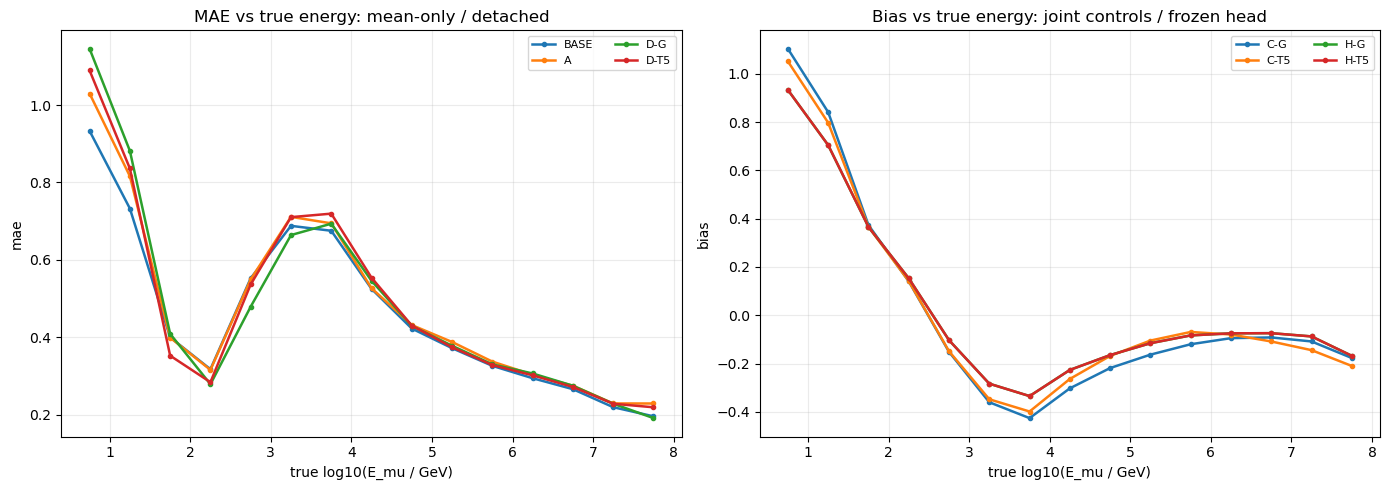

In [6]:
def binned_stats(df, bins=BINS, min_n=50):
    d = df[["true_log10e", "abs_err", "err"]].copy()
    d["bin_mid"] = pd.cut(
        d["true_log10e"], bins=bins, labels=(bins[:-1] + bins[1:]) / 2
    ).astype(float)
    g = (d.dropna(subset=["bin_mid"])
           .groupby("bin_mid", observed=True)
           .agg(n=("abs_err", "size"), mae=("abs_err", "mean"), bias=("err", "mean"))
           .reset_index())
    return g[g["n"] >= min_n]


def plot_energy_bins(ids, ax, value):
    cmap = plt.get_cmap("tab10")
    for i, rid in enumerate(ids):
        r = next((x for x in records if x["id"] == rid), None)
        if r is None:
            continue
        g = binned_stats(r["df"])
        ax.plot(g["bin_mid"], g[value], marker="o", ms=3, lw=1.8,
                color=cmap(i), label=rid)
    ax.set_xlabel("true log10(E_mu / GeV)")
    ax.set_ylabel(value)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, ncol=2)

MEAN_IDS = ["BASE", "A", "D-G", "D-T5"]
SIGMA_IDS = ["C-G", "C-T5", "H-G", "H-T5"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_energy_bins(MEAN_IDS, axes[0], "mae")
axes[0].set_title("MAE vs true energy: mean-only / detached")
plot_energy_bins(SIGMA_IDS, axes[1], "bias")
axes[1].set_title("Bias vs true energy: joint controls / frozen head")
fig.tight_layout()
fig.savefig(FIG_DIR / "error_vs_true_energy.png", dpi=150, bbox_inches="tight")
plt.show()


## Calibration versus energy and PIT

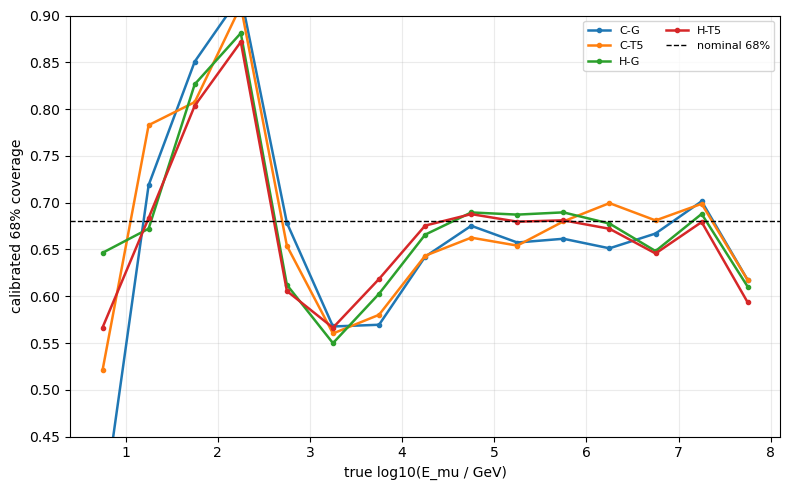

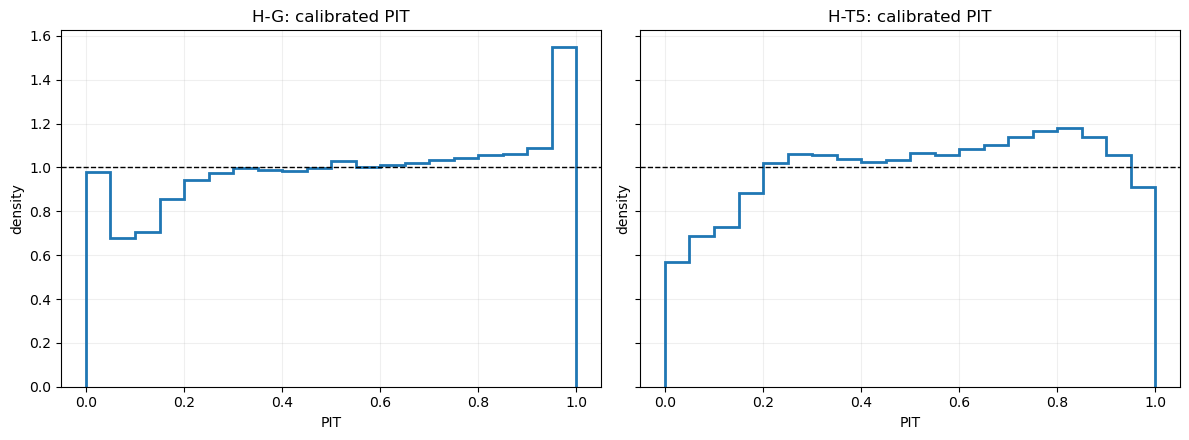

In [7]:
def calibrated_coverage_by_bin(df, r, bins=BINS, min_n=50):
    d = df[["true_log10e", "abs_err", "pred_sigma_dex"]].copy()
    d["bin_mid"] = pd.cut(
        d["true_log10e"], bins=bins, labels=(bins[:-1] + bins[1:]) / 2
    ).astype(float)
    d["covered68"] = d["abs_err"] <= d["pred_sigma_dex"] * r["q68"]
    g = (d.dropna(subset=["bin_mid"])
           .groupby("bin_mid", observed=True)
           .agg(n=("covered68", "size"), cov68=("covered68", "mean"))
           .reset_index())
    return g[g["n"] >= min_n]


fig, ax = plt.subplots(figsize=(8, 5))
cmap = plt.get_cmap("tab10")
for i, rid in enumerate(SIGMA_IDS):
    r = next((x for x in records if x["id"] == rid), None)
    if r is None or not r["has_sigma"]:
        continue
    g = calibrated_coverage_by_bin(r["df"], r)
    ax.plot(g["bin_mid"], g["cov68"], marker="o", ms=3, lw=1.8,
            color=cmap(i), label=rid)
ax.axhline(0.68, color="black", ls="--", lw=1, label="nominal 68%")
ax.set_xlabel("true log10(E_mu / GeV)")
ax.set_ylabel("calibrated 68% coverage")
ax.set_ylim(0.45, 0.90)
ax.grid(alpha=0.25)
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "coverage_vs_energy.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, rid in zip(axes, ["H-G", "H-T5"]):
    r = next((x for x in records if x["id"] == rid), None)
    if r is None or not r["has_sigma"]:
        continue
    pit = r["pit_cal"]
    ax.hist(pit, bins=np.linspace(0, 1, 21), density=True, histtype="step",
            lw=2, label=rid)
    ax.axhline(1.0, color="black", ls="--", lw=1)
    ax.set_title(f"{rid}: calibrated PIT")
    ax.set_xlabel("PIT")
    ax.set_ylabel("density")
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(FIG_DIR / "pit_frozen_heads.png", dpi=150, bbox_inches="tight")
plt.show()


## Binned by predicted energy

True-energy bins answer “where is the physics error?”. Predicted-energy bins answer
“what happens when we select events using the only variable available in data?”.
The two are not equivalent: regression migration puts events with different true
energies into the same predicted bin, and an analysis cut on reconstructed energy
acts on the predicted-energy profile.

The per-checkpoint notebooks contain the full predicted-energy set:
2D residual vs predicted energy, per-bin MAE/bias, per-bin sigma coverage and
sigma-vs-predicted-energy.  Here is the cross-model view.

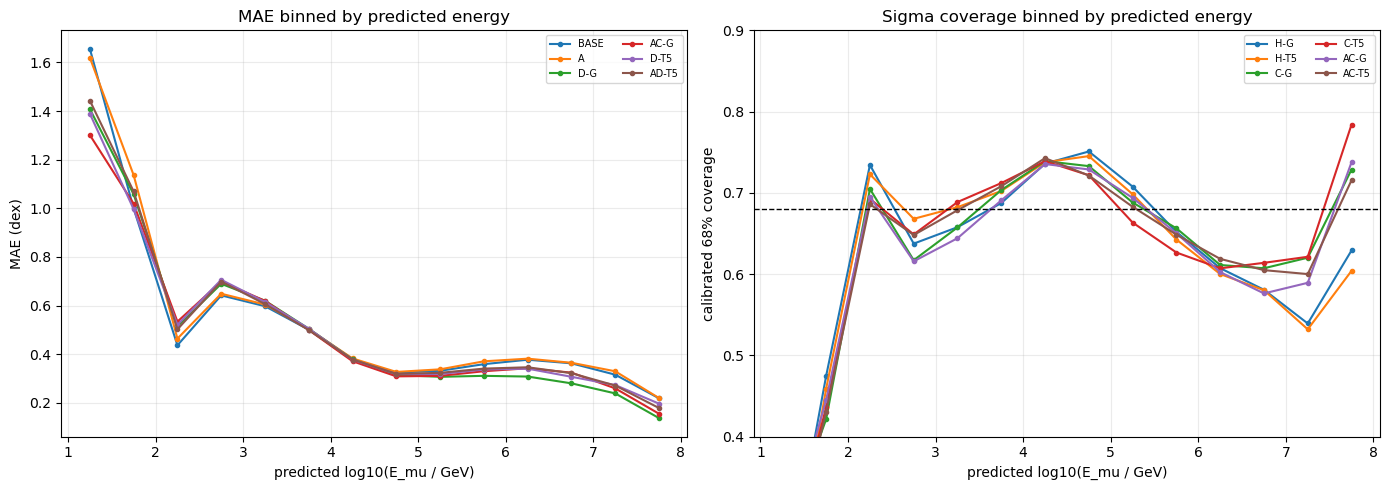

In [8]:
def predicted_bin_stats(r, min_n=50):
    d = r["df"][["pred_log10e", "abs_err", "err", "pred_sigma_dex"]].copy()
    d["bin_mid"] = pd.cut(
        d["pred_log10e"], bins=BINS, labels=(BINS[:-1] + BINS[1:]) / 2
    ).astype(float)
    rows = []
    for mid, g in d.dropna(subset=["bin_mid"]).groupby("bin_mid", observed=True):
        row = {"bin_mid": float(mid), "n": len(g),
               "mae": float(g["abs_err"].mean()),
               "bias": float(g["err"].mean())}
        if r["has_sigma"]:
            sig = g["pred_sigma_dex"].to_numpy(np.float64)
            err = g["abs_err"].to_numpy(np.float64)
            row["cal68"] = float(np.mean(err <= sig * r["q68"]))
        rows.append(row)
    out = pd.DataFrame(rows).sort_values("bin_mid")
    return out[out["n"] >= min_n]


PRED_MEAN_IDS = ["BASE", "A", "D-G", "AC-G", "D-T5", "AD-T5"]
PRED_SIGMA_IDS = ["H-G", "H-T5", "C-G", "C-T5", "AC-G", "AC-T5"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, rid in enumerate(PRED_MEAN_IDS):
    r = next((x for x in records if x["id"] == rid), None)
    if r is None: continue
    g = predicted_bin_stats(r)
    axes[0].plot(g["bin_mid"], g["mae"], marker="o", ms=3, lw=1.5,
                 color=plt.cm.tab10(i), label=rid)
axes[0].set_xlabel("predicted log10(E_mu / GeV)")
axes[0].set_ylabel("MAE (dex)")
axes[0].set_title("MAE binned by predicted energy")
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=7, ncol=2)

for i, rid in enumerate(PRED_SIGMA_IDS):
    r = next((x for x in records if x["id"] == rid), None)
    if r is None or not r["has_sigma"]: continue
    g = predicted_bin_stats(r)
    axes[1].plot(g["bin_mid"], g["cal68"], marker="o", ms=3, lw=1.5,
                 color=plt.cm.tab10(i), label=rid)
axes[1].axhline(0.68, color="black", ls="--", lw=1)
axes[1].set_xlabel("predicted log10(E_mu / GeV)")
axes[1].set_ylabel("calibrated 68% coverage")
axes[1].set_ylim(0.40, 0.90)
axes[1].set_title("Sigma coverage binned by predicted energy")
axes[1].grid(alpha=0.25)
axes[1].legend(fontsize=7, ncol=2)

fig.tight_layout()
fig.savefig(FIG_DIR / "coverage_vs_predicted_energy.png", dpi=150, bbox_inches="tight")
plt.show()


## Mean versus NLL

NLL/coverage for `H/AH` are selected by `val_unc_nll`; `D/C` are selected by
`val_mae`.  This plot is therefore a **Pareto view**, not a controlled comparison.

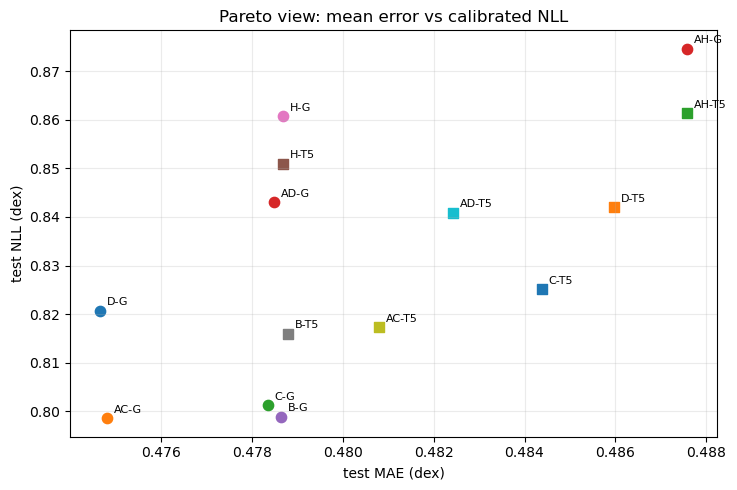

,id,mae,rmse,bias,nll_cal,cal68,cal95
1,AC-G,0.4748,0.6614,-0.1564,0.7986,0.6766,0.9472
4,B-G,0.4786,0.6683,-0.1436,0.7989,0.6779,0.9473
2,C-G,0.4784,0.6710,-0.1780,0.8013,0.6788,0.9483
7,B-T5,0.4788,0.6783,-0.1503,0.8159,0.6782,0.9490
8,AC-T5,0.4808,0.6799,-0.1500,0.8173,0.6762,0.9472
0,D-G,0.4747,0.6615,-0.1684,0.8207,0.6757,0.9459
10,C-T5,0.4844,0.6845,-0.1500,0.8251,0.6744,0.9469
9,AD-T5,0.4824,0.6819,-0.1484,0.8409,0.6757,0.9465
11,D-T5,0.4860,0.6871,-0.1654,0.8420,0.6746,0.9462
3,AD-G,0.4785,0.6668,-0.1685,0.8430,0.6752,0.9490


In [9]:
comp = metrics[["id", "mae", "rmse", "bias"]].merge(
    calibration[["id", "nll_cal", "cal68", "cal95"]], on="id", how="inner"
)
fig, ax = plt.subplots(figsize=(7.5, 5))
for _, row in comp.iterrows():
    marker = "o" if row["id"].endswith("-G") else "s"
    ax.scatter(row["mae"], row["nll_cal"], s=55, marker=marker)
    ax.annotate(row["id"], (row["mae"], row["nll_cal"]),
                textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.set_xlabel("test MAE (dex)")
ax.set_ylabel("test NLL (dex)")
ax.grid(alpha=0.25)
ax.set_title("Pareto view: mean error vs calibrated NLL")
fig.tight_layout()
fig.savefig(FIG_DIR / "mae_vs_nll.png", dpi=150, bbox_inches="tight")
plt.show()

display(comp.sort_values("nll_cal").round(4))


## DA diagnostics from training history

This is the training-history view, not the energy prediction DB.  The linear probe
and MLP are retrained during training; the MLP convergence itself is a separate
issue.  The dashed line marks the epoch where `da_coef` first becomes positive.

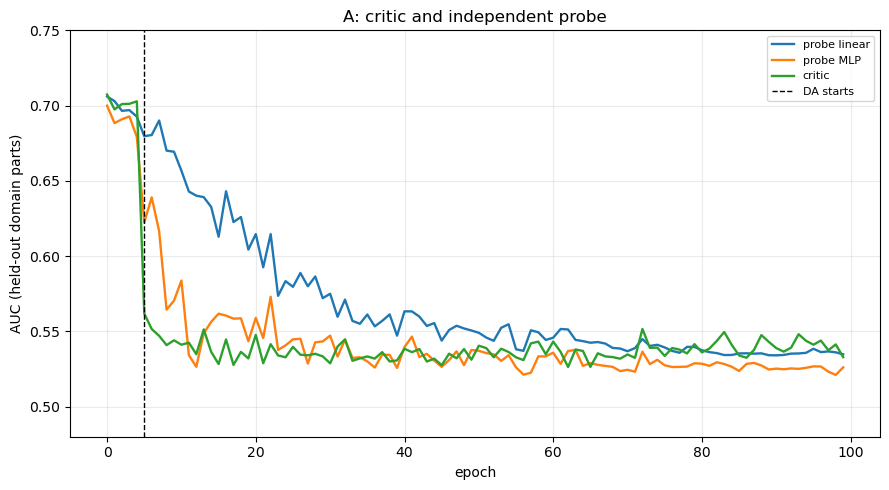

In [10]:
a_run = next((x for x in records if x["id"] == "A"), None)
if a_run is not None:
    hist_path = TRAIN_ROOT / a_run["run"] / "training_history.csv"
    hist = pd.read_csv(hist_path)
    fig, ax = plt.subplots(figsize=(9, 5))
    for col, label in [
        ("val_domain_probe_auc", "probe linear"),
        ("val_domain_probe_mlp_auc", "probe MLP"),
        ("val_domain_critic_auc", "critic"),
    ]:
        if col in hist:
            ax.plot(hist["epoch"], hist[col], lw=1.7, label=label)
    if "da_coef" in hist:
        da_epochs = hist.loc[hist["da_coef"].fillna(0) > 0, "epoch"]
        if len(da_epochs):
            ax.axvline(float(da_epochs.min()), color="black", ls="--", lw=1,
                       label="DA starts")
    ax.set_xlabel("epoch")
    ax.set_ylabel("AUC (held-out domain parts)")
    ax.set_ylim(0.48, 0.75)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
    ax.set_title("A: critic and independent probe")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "A_da_diagnostics.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("A run not loaded")


## Converged domain probe

The per-epoch MLP in `training_history.csv` is under-trained (`max_iter=200`,
`early_stopping=True`, no feature scaling).  `analysis/domain_probe.py` refits a
standardised linear probe and a larger MLP (256x128, max_iter=2000, three seeds)
on the same held-out DA events.  It reports both an event-level split inside the
DA-held-out parts and a **part-disjoint** split, where whole part keys go to
either fit or test.  The part-disjoint number is the primary check; event-level
is kept for comparison with the training history.

`da_enabled` describes the **encoder**, not whether the current head-training
stage had DA on.  Thus `AH-*` is DA: it inherits the encoder from `A`, and its
probe row is a duplicate of `A`, not a no-DA control.

,id,da_enabled,linear_auc,linear_auc_part,original_mlp_auc,mlp_auc_mean,mlp_auc_mean_part,mlp_auc_std,mlp_auc_std_part,mlp_n_iter_mean,mlp_n_iter_mean_part
0,BASE,False,0.6832,0.6783,0.5841,0.6695,0.6647,0.0159,0.0080,99.0000,70.6667
1,A,True,0.6309,0.6066,0.5286,0.6055,0.5985,0.0028,0.0007,117.6667,133.3333
2,D-G,False,0.7318,0.7091,0.6356,0.7319,0.7031,0.0041,0.0045,60.0000,65.0000
3,D-T5,False,0.7025,0.6921,0.5610,0.7005,0.6874,0.0018,0.0056,66.0000,73.0000
4,C-G,False,0.7017,0.6880,0.5567,0.6677,0.6524,0.0043,0.0046,98.0000,69.6667
5,C-T5,False,0.7029,0.6879,0.5614,0.6838,0.6722,0.0030,0.0049,68.0000,70.3333
6,B-G,False,0.7064,0.6910,0.6108,0.6808,0.6857,0.0072,0.0024,71.3333,69.0000
7,B-T5,False,0.7057,0.6892,0.6417,0.6948,0.6895,0.0083,0.0051,64.0000,81.6667
8,AD-G,True,0.6659,0.6385,0.5283,0.6415,0.6432,0.0108,0.0018,74.6667,122.0000
9,AD-T5,True,0.6830,0.6665,0.5397,0.6540,0.6259,0.0062,0.0067,80.0000,61.3333


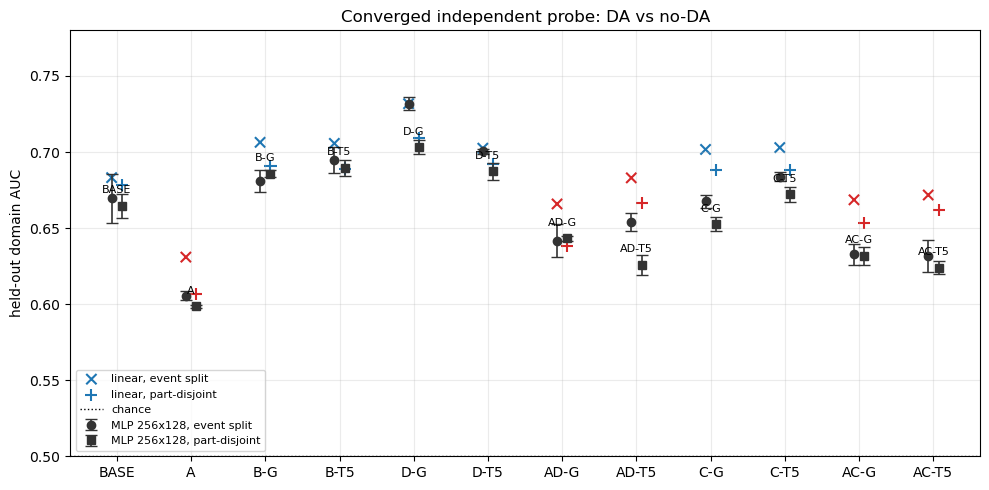

A vs BASE event split:  MLP 0.669 -> 0.606 (delta -0.064); linear 0.683 -> 0.631
A vs BASE part split:   MLP 0.665 -> 0.599 (delta -0.066); linear 0.678 -> 0.607


In [11]:
probe_path = REPORT_DIR / "da_probe.csv"
if probe_path.exists():
    probe = pd.read_csv(probe_path)
    display(probe[["id", "da_enabled", "linear_auc", "linear_auc_part",
                   "original_mlp_auc", "mlp_auc_mean", "mlp_auc_mean_part",
                   "mlp_auc_std", "mlp_auc_std_part", "mlp_n_iter_mean",
                   "mlp_n_iter_mean_part"]].round(4))

    order = [x for x in ["BASE", "A", "B-G", "B-T5", "AB-G", "AB-T5",
                         "D-G", "D-T5", "AD-G", "AD-T5", "C-G", "C-T5",
                         "AC-G", "AC-T5"] if x in set(probe["id"])]
    p = probe.set_index("id").loc[order].reset_index()
    x = np.arange(len(p))
    fig, ax = plt.subplots(figsize=(10, 5))
    colors = ["#d62728" if bool(v) else "#1f77b4" for v in p["da_enabled"]]
    ax.errorbar(x - 0.07, p["mlp_auc_mean"], yerr=p["mlp_auc_std"], fmt="o",
                ms=6, capsize=4, lw=1.2, color="#333333",
                label="MLP 256x128, event split")
    ax.errorbar(x + 0.07, p["mlp_auc_mean_part"], yerr=p["mlp_auc_std_part"],
                fmt="s", ms=6, capsize=4, lw=1.2, color="#333333",
                label="MLP 256x128, part-disjoint")
    ax.scatter(x - 0.07, p["linear_auc"], marker="x", s=55, color=colors,
               label="linear, event split")
    ax.scatter(x + 0.07, p["linear_auc_part"], marker="+", s=75, color=colors,
               label="linear, part-disjoint")
    for xi, row in zip(x, p.itertuples()):
        ax.annotate(row.id, (xi, row.mlp_auc_mean_part), textcoords="offset points",
                    xytext=(0, 9), ha="center", fontsize=8)
    ax.axhline(0.5, color="black", ls=":", lw=1, label="chance")
    ax.set_xticks(x)
    ax.set_xticklabels(p["id"])
    ax.set_ylim(0.50, 0.78)
    ax.set_ylabel("held-out domain AUC")
    ax.set_title("Converged independent probe: DA vs no-DA")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, loc="lower left")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "da_probe_converged.png", dpi=150, bbox_inches="tight")
    plt.show()

    if {"BASE", "A"}.issubset(set(p["id"])):
        b = p.set_index("id").loc["BASE"]
        a = p.set_index("id").loc["A"]
        print(f"A vs BASE event split:  MLP {b.mlp_auc_mean:.3f} -> {a.mlp_auc_mean:.3f} "
              f"(delta {a.mlp_auc_mean - b.mlp_auc_mean:+.3f}); "
              f"linear {b.linear_auc:.3f} -> {a.linear_auc:.3f}")
        print(f"A vs BASE part split:   MLP {b.mlp_auc_mean_part:.3f} -> {a.mlp_auc_mean_part:.3f} "
              f"(delta {a.mlp_auc_mean_part - b.mlp_auc_mean_part:+.3f}); "
              f"linear {b.linear_auc_part:.3f} -> {a.linear_auc_part:.3f}")
else:
    print("da_probe.csv not found; run analysis/domain_probe.py")

## Per-checkpoint detail notebooks

The summary above is intentionally cross-run.  Per-checkpoint notebooks live in
`analysis/by_checkpoint/<run>@best_model.ipynb`.  They open the same test DB and add
the detailed views: 2D residual-vs-true-energy, 2D prediction-vs-truth, per-bin
MAE/bias, per-class tables, predicted-energy bins and the converged domain probe.
A separate `## Sigma analysis` block adds coverage versus true and predicted
energy, global and energy-binned PIT, sigma-versus-predicted-energy, and the
signed/absolute error ranking with global and within-bin correlations.  Their
CSV/JSON/figures are under `analysis/reports/by_checkpoint/<run>@best_model/`.

Currently generated for the 16 runs with test DBs.  `AB-G`/`AB-T5` will be added
by the same wrappers after their phase-2 predictions complete.

## Notes and limitations

- This notebook only covers test-part MC.  It does not test experimental energy
  truth (none exists) and does not test atmospheric-muon energy (the energy test
  parts contain `nuatm`/`nue2` only).
- `H/AH` mean is frozen from the base model; their MAE is identical to the base by
  construction.  They are candidates for uncertainty, not for improving mean.
- `H/AH` sigma heads were trained on the base model's training events.  Test
  coverage is close to nominal after calibration, but conditional coverage and
  the head-fit protocol still need attention.  Predicted-energy binning exposes
  migration: for `H-T5`, calibrated 68% coverage is 0.804 in the true 1.75-dex bin
  but 0.459 in the predicted 1.75-dex bin, where the events are mostly
  catastrophically underestimated.  A cut on reconstructed energy acts on that
  harder conditional population.
- `D/C` checkpoints are selected by `val_mae`; `H/AH` by `val_unc_nll`.  The
  MAE-vs-NLL plot is a Pareto view, not an apples-to-apples sigma comparison.
- The MLP probe in training history is under-trained: `max_iter=200`,
  `early_stopping=True`, no feature scaling.  Do not treat
  `val_domain_probe_mlp_auc` as a certificate.  `analysis/domain_probe.py`
  provides the converged probe used in the DA comparison.
- The converged probe has two splits: event-level inside the held-out DA parts
  (comparable with training history) and part-disjoint (whole part keys go to fit
  or test).  The part-disjoint AUC is the primary check; it is a held-out
  measurement, not a proof of domain invariance.
- `AB-G`/`AB-T5` are absent until their training and phase-2 predictions finish.

Generated tables: `reports/prediction_manifest.csv`, `reports/summary_metrics.csv`,
`reports/class_metrics.csv`, `reports/calibration_metrics.csv`.  Figures:
`reports/figures/`.